## FinanceDataReader란?
한국 주식 가격, 미국주식 가격, 지수, 환율, 암호화례 가격, 종목 리스팅 등 금융 데이터 수집 라이브러리

In [9]:
# !pip install -U finance-datareader

In [10]:
import FinanceDataReader as fdr
fdr.__version__

'0.9.202'

In [11]:
# 도움말을 보고자 할때는 ?를 사용
fdr.StockListing?

Signature: fdr.StockListing(market: str, start=None, end=None) -> pandas.core.frame.DataFrame
Docstring:
read stock list of stock exchanges
* market: 'KRX', 'KOSPI', 'KOSDAQ', 'KONEX', 'KRX-MARCAP', 
        'KRX-DESC', 'KOSPI-DESC', 'KOSDAQ-DESC', 'KONEX-DESC',
        'KRX-DELISTING', 'KRX-ADMINISTRATIVE', 'KRX-MARCAP',
        'NASDAQ', 'NYSE', 'AMEX', 'SSE', 'SZSE', 'HKEX', 'TSE', 'HOSE',
        'S&P500',
        'ETF/KR',
File:      c:\users\kosa\anaconda3\lib\site-packages\financedatareader\data.py
Type:      function

In [12]:
# KRX : KRX 종목 전체
# KOSPI : KOSPI 종목
# KOSDAQ : KOSDAQ 종목
# KONEX : KONEX 종목
# KRX-MARCAP : 나스닥 종목
# NYSE : 뉴욕증권거애소 종목
# S&P500 : S&P500 종목

df_krx = fdr.StockListing("KRX")

In [13]:
# 한국거래소 상장종목 전체 가져오기
df_krx.head()

,Code,ISU_CD,Name,Market,Dept,Close,ChangeCode,Changes,ChagesRatio,Open,High,Low,Volume,Amount,Marcap,Stocks,MarketId,lateInfoMsgCd
0,060310,KR7060310000,3S,KOSDAQ,벤처기업부,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53059040,KSQ,ME005
1,095570,KR7095570008,AJ네트웍스,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45252759,STK,ME005
2,006840,KR7006840003,AK홀딩스,KOSPI,NaN,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13247561,STK,ME005
3,054620,KR7054620000,APS,KOSDAQ,중견기업부,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18394221,KSQ,ME005
4,079810,KR7079810008,APS이노베이션,KOSDAQ,우량기업부,-,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21528094,KSQ,ME005


### 라이브러리 로드

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

## 삼성전자 일별시세 불러오기

In [20]:
df = fdr.DataReader("005930", "2020", "2021")
df.shape

(248, 6)

In [23]:
# 일별 시세 확인 - 오픈가, 상한가, 하한가, 종료가, 거래량, 전일 대비 상승 하락 비율
df.head()

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2020-01-02,55500,56000,55000,55200,12993228,-0.010753
2020-01-03,56000,56600,54900,55500,15422255,0.005435
2020-01-06,54900,55600,54600,55500,10278951,0.000000
2020-01-07,55700,56400,55600,55800,10009778,0.005405
2020-01-08,56200,57400,55900,56800,23501171,0.017921


In [24]:
df.tail()

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2020-12-23,72400,74000,72300,73900,19411326,0.022130
2020-12-24,74100,78800,74000,77800,32502870,0.052774
2020-12-28,79000,80100,78200,78700,40085044,0.011568
2020-12-29,78800,78900,77300,78300,30339449,-0.005083
2020-12-30,77400,81300,77300,81000,29417421,0.034483


## Shift를 활용해 전일 대비 수익률 구하기
* Change값 직접 구해보기

In [26]:
df["Close"].shift(1)

Date
2020-01-02        NaN
2020-01-03    55200.0
2020-01-06    55500.0
2020-01-07    55500.0
2020-01-08    55800.0
               ...   
2020-12-23    72300.0
2020-12-24    73900.0
2020-12-28    77800.0
2020-12-29    78700.0
2020-12-30    78300.0
Name: Close, Length: 248, dtype: float64

In [27]:
# change = (종가 / 전일 종가) -1
df["Change2"] = df["Close"] / df["Close"].shift(1) -1

In [30]:
# 전익 대비 수익률
# 불러온 값과 직접 구한 값이 같은지 확인
df[["Change", "Change2"]].head()

,Change,Change2
Date,,
2020-01-02,-0.010753,NaN
2020-01-03,0.005435,0.005435
2020-01-06,0.000000,0.000000
2020-01-07,0.005405,0.005405
2020-01-08,0.017921,0.017921


In [31]:
# pct_change 값 직접 구하기
# pct_change = (종가 / 전일 종가) -1
df["pct_chage"] = df["Close"].pct_change()
df.head()

,Open,High,Low,Close,Volume,Change,Change2,pct_chage
Date,,,,,,,,
2020-01-02,55500,56000,55000,55200,12993228,-0.010753,NaN,NaN
2020-01-03,56000,56600,54900,55500,15422255,0.005435,0.005435,0.005435
2020-01-06,54900,55600,54600,55500,10278951,0.000000,0.000000,0.000000
2020-01-07,55700,56400,55600,55800,10009778,0.005405,0.005405,0.005405
2020-01-08,56200,57400,55900,56800,23501171,0.017921,0.017921,0.017921


In [32]:
# Diff 값 구하기
df["Diff"] = df["Close"].diff()

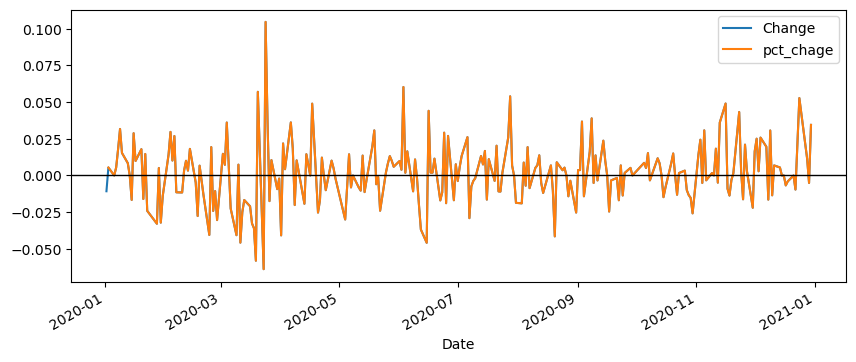

In [34]:
df[["Change", "pct_chage"]].plot(figsize = (10, 4))
plt.axhline(0, c = "k", lw = 1)